# Rewriting a Poem with Word2Vec Associates

**Course:** Natural Language Processing
**Task:** Replace every content word (noun, verb, adjective, adverb) of a short poem with its
closest semantic associate from a pretrained Word2Vec model, keep the grammatical form,
and analyse how the meaning changes.

## 0. First

In [1]:
import re
import string
import nltk
import pandas as pd
import gensim.downloader as api
from lemminflect import getInflection, getLemma
for resource in ("punkt", "punkt_tab",
                 "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"):
    nltk.download(resource, quiet=True)

## 1. The poem

An original four-line poem written for this assignment.
It contains nouns, verbs in the past tense, plural nouns, adverbs, and two
verb-derived adjectives ("winding", "dying"), which makes it a good test of form preservation.

In [2]:
POEM = """The morning light crept slowly over quiet hills,
Where gentle rivers carried sleepy clouds away.
A lonely traveler walked along the winding road,
And softly hummed a song about the dying day."""

print(POEM)

The morning light crept slowly over quiet hills,
Where gentle rivers carried sleepy clouds away.
A lonely traveler walked along the winding road,
And softly hummed a song about the dying day.


## 2. Load the pretrained Word2Vec model

`word2vec-google-news-300` was trained on about 100 billion words of Google News.
It has 3 million vocabulary entries (words and phrases) with 300-dimensional vectors.

In [3]:
model = api.load("word2vec-google-news-300")
print(f"Vocabulary size: {len(model.key_to_index):,} | vector size: {model.vector_size}")

Vocabulary size: 3,000,000 | vector size: 300


## 3. Preprocessing

As specified: lowercase, remove punctuation, split into words.
Line breaks are kept so the rewritten poem has the same layout as the original.

In [4]:
def preprocess_line(line: str) -> list[str]:
    """Lowercase, remove punctuation, split on whitespace."""
    line = line.lower()
    line = line.translate(str.maketrans("", "", string.punctuation))
    return line.split()


poem_lines = [preprocess_line(line) for line in POEM.splitlines()]
for tokens in poem_lines:
    print(tokens)

['the', 'morning', 'light', 'crept', 'slowly', 'over', 'quiet', 'hills']
['where', 'gentle', 'rivers', 'carried', 'sleepy', 'clouds', 'away']
['a', 'lonely', 'traveler', 'walked', 'along', 'the', 'winding', 'road']
['and', 'softly', 'hummed', 'a', 'song', 'about', 'the', 'dying', 'day']


## 4. Identify content words

We POS-tag each line with NLTK's perceptron tagger (Penn Treebank tags) and keep:

| Penn tags | Category |
|---|---|
| `NN, NNS` (proper nouns excluded) | noun |
| `VB, VBD, VBG, VBN, VBP, VBZ` | verb |
| `JJ, JJR, JJS` | adjective |
| `RB, RBR, RBS` | adverb |

Everything else (determiners, prepositions, conjunctions, ...) is a function word and stays unchanged.
Auxiliary verbs (*be, have, do*) are also treated as function words.

In [5]:
CONTENT_PREFIXES = ("NN", "VB", "JJ", "RB")
EXCLUDED_TAGS = {"NNP", "NNPS"}            # proper nouns
AUXILIARIES = {"be", "am", "is", "are", "was", "were", "been", "being",
               "have", "has", "had", "having", "do", "does", "did"}

# Penn tag -> universal POS expected by lemminflect
PENN_TO_UPOS = {"N": "NOUN", "V": "VERB", "J": "ADJ", "R": "ADV"}


def is_content(word: str, tag: str) -> bool:
    return (tag.startswith(CONTENT_PREFIXES)
            and tag not in EXCLUDED_TAGS
            and word not in AUXILIARIES)


def tag_line(tokens: list[str]) -> list[tuple[str, str, bool]]:
    """Return (word, penn_tag, is_content_word) for each token."""
    return [(w, t, is_content(w, t)) for w, t in nltk.pos_tag(tokens)]


tagged_lines = [tag_line(tokens) for tokens in poem_lines]

tag_table = pd.DataFrame(
    [(i + 1, w, t, c) for i, line in enumerate(tagged_lines) for w, t, c in line],
    columns=["line", "word", "penn_tag", "content_word"],
)
tag_table

,line,word,penn_tag,content_word
0,1,the,DT,False
1,1,morning,NN,True
2,1,light,NN,True
3,1,crept,NN,True
4,1,slowly,RB,True
5,1,over,IN,False
6,1,quiet,JJ,True
7,1,hills,NNS,True
8,2,where,WRB,False
9,2,gentle,JJ,True


### Sanity check against a manual annotation

Automatic taggers make mistakes, especially on lowercased text without punctuation.
I annotated the poem by hand beforehand; any disagreement is printed so it can be reviewed.
Words in `EXPECTED_CONTENT` should be flagged as content words; all other words should not.

In [6]:
EXPECTED_CONTENT = {
    "morning", "light", "crept", "slowly", "quiet", "hills",
    "gentle", "rivers", "carried", "sleepy", "clouds", "away",
    "lonely", "traveler", "walked", "winding", "road",
    "softly", "hummed", "song", "dying", "day",
}

detected = {w for line in tagged_lines for w, _, c in line if c}
print("Missed by tagger  :", sorted(EXPECTED_CONTENT - detected) or "none")
print("Extra from tagger :", sorted(detected - EXPECTED_CONTENT) or "none")

Missed by tagger  : ['away']
Extra from tagger : none


If the tagger disagrees with the manual annotation, discuss it in the write-up
(for example "away" can be tagged as an adverb or a particle).
You may also override tags manually, but report that you did.

## 5. Finding associates

For each content word we query `model.most_similar(word, topn=1)`.

### Why not blindly take the top-1 neighbour?
Raw Word2Vec neighbours often contain noise that would break the task:
* **Same word, different surface form** (`hills` -> `hill`), which is not a real replacement.
* **Capitalised or multi-word entries** (`Hills`, `rolling_hills`).
* **Tokens containing digits or punctuation.**

We therefore look at the top-`K` neighbours and take the **first valid** one. If the very first
neighbour is valid (the usual case) this is exactly top-1. Both the raw top-1 and the chosen
associate are recorded in the results table, so the effect of the filter is visible.

### Keeping the grammatical form
GoogleNews vectors are not lemmatised, so we
1. reduce the original word to its lemma (`carried` -> `carry`) and query the model with the
   **original surface form first**, falling back to the lemma if it is out of vocabulary;
2. re-inflect the chosen associate to the original Penn tag
   (`carry` + `VBD` -> `carried`, `hill` + `NNS` -> `hills`).

In [7]:
TOP_K = 15   # how many neighbours to scan when looking for the first valid one


def upos_of(tag: str) -> str:
    return PENN_TO_UPOS[tag[0]]


def lemma_of(word: str, tag: str) -> str:
    lemmas = getLemma(word, upos=upos_of(tag))
    return lemmas[0] if lemmas else word


def is_valid_candidate(candidate: str, original_word: str, original_tag: str) -> bool:
    """A neighbour is acceptable if it is a single, lowercase, purely alphabetic word
    and not just another inflection of the original word."""
    if "_" in candidate or not candidate.isalpha() or not candidate.islower():
        return False
    return lemma_of(candidate, original_tag) != lemma_of(original_word, original_tag)


def best_associate(word: str, tag: str):
    """Return (raw_top1, chosen_associate_lemma) or (None, None) if the word is OOV."""
    # 1. choose the query key that exists in the vocabulary
    for key in (word, lemma_of(word, tag)):
        if key in model.key_to_index:
            query = key
            break
    else:
        return None, None

    neighbours = [w for w, _ in model.most_similar(query, topn=TOP_K)]
    raw_top1 = neighbours[0]
    for cand in neighbours:
        if is_valid_candidate(cand, word, tag):
            return raw_top1, lemma_of(cand, tag)
    return raw_top1, None


def reinflect(lemma: str, tag: str) -> str:
    """Put an associate (given as a lemma) into the grammatical form of the original tag."""
    if tag in {"NN", "VB", "JJ", "RB"}:          # base forms need no inflection
        return lemma
    forms = getInflection(lemma, tag=tag)
    return forms[0] if forms else lemma

## 6. Rewrite the poem

Function words and line breaks are preserved. Out-of-vocabulary content words are kept unchanged
and reported in the table.

In [8]:
records = []           # one row per content word, used for the analysis below
new_lines = []

for line_no, line in enumerate(tagged_lines, start=1):
    out_tokens = []
    for word, tag, content in line:
        if not content:
            out_tokens.append(word)
            continue

        raw_top1, associate_lemma = best_associate(word, tag)
        if associate_lemma is None:
            new_word, status = word, "OOV / no valid neighbour"
        else:
            new_word, status = reinflect(associate_lemma, tag), "replaced"

        out_tokens.append(new_word)
        records.append({
            "line": line_no, "original": word, "tag": tag,
            "raw_top1": raw_top1, "associate": new_word, "status": status,
        })
    new_lines.append(out_tokens)

results = pd.DataFrame(records)
results

,line,original,tag,raw_top1,associate,status
0,1,morning,NN,afternoon,afternoon,replaced
1,1,light,NN,lights,illumination,replaced
2,1,crept,NN,creeping,creeping,replaced
3,1,slowly,RB,gradually,gradually,replaced
4,1,quiet,JJ,calm,calm,replaced
5,1,hills,NNS,mountains,mountains,replaced
6,2,gentle,JJ,gentlest,gentlen,replaced
7,2,rivers,NNS,tributaries,tributaries,replaced
8,2,carried,VBD,carry,conducted,replaced
9,2,sleepy,JJ,somnolent,somnolent,replaced


## 7. Result: original vs rewritten poem

In [9]:
def render(lines: list[list[str]]) -> str:
    """Capitalise the first word of each line for readability."""
    return "\n".join(" ".join(t).capitalize() for t in lines)


print("ORIGINAL\n" + "-" * 8)
print(render(poem_lines))
print("\nREWRITTEN WITH WORD2VEC ASSOCIATES\n" + "-" * 34)
print(render(new_lines))

ORIGINAL
--------
The morning light crept slowly over quiet hills
Where gentle rivers carried sleepy clouds away
A lonely traveler walked along the winding road
And softly hummed a song about the dying day

REWRITTEN WITH WORD2VEC ASSOCIATES
----------------------------------
The afternoon illumination creeping gradually over calm mountains
Where gentlen tributaries conducted somnolent thunderclouds away
A lonesome vacationer strode along the meandering highway
And calmly thrummed a lyric about the perishing week


## 8. Quantitative evaluation

Two simple measures of how far the meaning moved:
* **Word level:** cosine similarity between each original word and its replacement.
  High values (close to 1) mean a near-synonym or a close relative, and low values mean topic drift.
* **Line level:** cosine similarity between the *average vector* of the original line and of the
  rewritten line (a bag-of-vectors sentence representation).

In [10]:
import numpy as np


def word_sim(a: str, b: str):
    if a in model.key_to_index and b in model.key_to_index:
        return float(model.similarity(a, b))
    return np.nan


results["cosine_sim"] = [word_sim(o, a) for o, a in zip(results.original, results.associate)]
print(results[["original", "associate", "cosine_sim"]].round(3).to_string(index=False))
print(f"\nMean word-level similarity: {results.cosine_sim.mean():.3f}")


def line_vector(tokens: list[str]):
    vecs = [model[t] for t in tokens if t in model.key_to_index]
    return np.mean(vecs, axis=0) if vecs else None


def cosine(u, v) -> float:
    return float(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v)))


line_scores = []
for i, (old, new) in enumerate(zip(poem_lines, new_lines), start=1):
    u, v = line_vector(old), line_vector(new)
    line_scores.append(cosine(u, v) if u is not None and v is not None else np.nan)
    print(f"Line {i}: line-level cosine similarity = {line_scores[-1]:.3f}")

original     associate  cosine_sim
 morning     afternoon       0.885
   light  illumination       0.534
   crept      creeping       0.726
  slowly     gradually       0.765
   quiet          calm       0.628
   hills     mountains       0.749
  gentle       gentlen         NaN
  rivers   tributaries       0.794
 carried     conducted       0.544
  sleepy     somnolent       0.597
  clouds thunderclouds       0.640
  lonely      lonesome       0.660
traveler    vacationer       0.590
  walked        strode       0.694
 winding    meandering       0.473
    road       highway       0.697
  softly        calmly       0.581
  hummed      thrummed       0.602
    song         lyric       0.743
   dying     perishing       0.523
     day          week       0.655

Mean word-level similarity: 0.654
Line 1: line-level cosine similarity = 0.833
Line 2: line-level cosine similarity = 0.746
Line 3: line-level cosine similarity = 0.794
Line 4: line-level cosine similarity = 0.775


## 9. Visualisation

Original words and their associates projected to 2-D with PCA.
Arrows show how each word "moved" in embedding space.

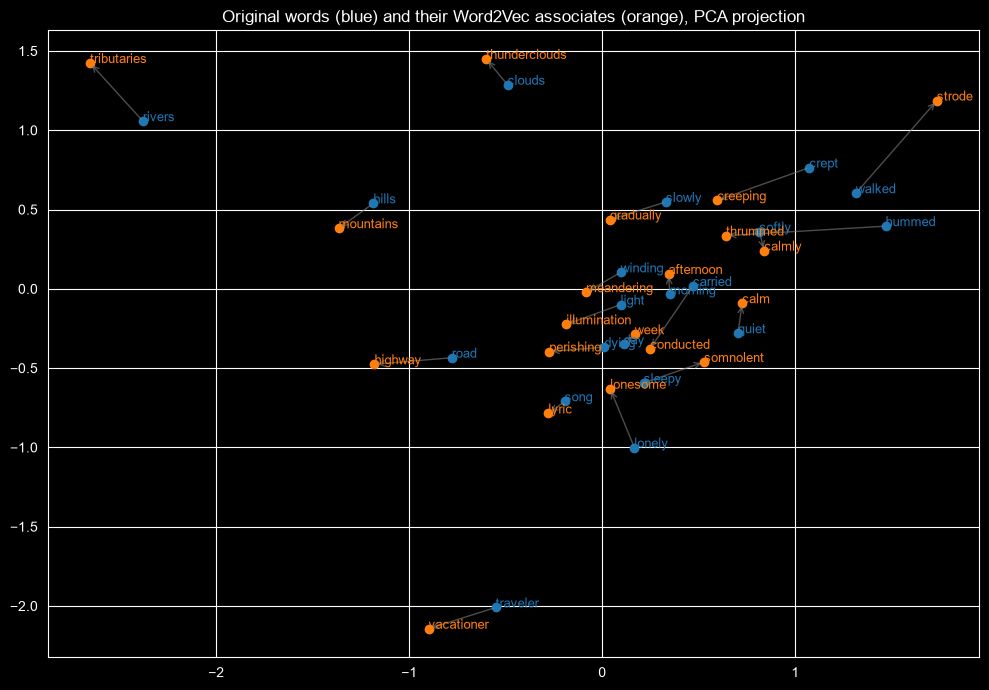

In [11]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pairs = [(o, a) for o, a in zip(results.original, results.associate)
         if o in model.key_to_index and a in model.key_to_index]
words = [w for pair in pairs for w in pair]
coords = PCA(n_components=2).fit_transform(np.array([model[w] for w in words]))

fig, ax = plt.subplots(figsize=(10, 7))
for i, (o, a) in enumerate(pairs):
    (x1, y1), (x2, y2) = coords[2 * i], coords[2 * i + 1]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="gray", alpha=0.6))
    ax.scatter(x1, y1, color="tab:blue")
    ax.scatter(x2, y2, color="tab:orange")
    ax.text(x1, y1, o, color="tab:blue", fontsize=9)
    ax.text(x2, y2, a, color="tab:orange", fontsize=9)
ax.set_title("Original words (blue) and their Word2Vec associates (orange), PCA projection")
plt.tight_layout()
plt.show()

## Conclusion
Overall, the new poem kept a similar topic and mood, and the grammar stayed correct because I matched the tense and number of each original word. That shows Word2Vec is good at finding words that are used in similar contexts.
It was less good at keeping the exact meaning. Many replacements were related to the original word but not true synonyms, so some of the poem's imagery changed or was lost. Word2Vec also gives each word only one vector, so it can't tell the different meanings of a word apart and doesn't use the context of the sentence. The model was trained on news text too, which is quite different from poetry.
In short, the exercise showed that words being close in vector space doesn't always mean they mean the same thing. A contextual model like BERT would probably give better replacements.